In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pycwt as wavelet
from pycwt.helpers import find

df = pd.read_excel('./data/Dabie_data.xlsx')

In [2]:
df

,Age,Thickness
0,120.4,79.304867
1,120.7,48.126964
2,121.8,56.357422
3,122.5,62.545913
4,122.6,59.395366
...,...,...
4899,3446.0,29.679293
4900,3508.3,52.163810
4901,3570.1,33.714328
4902,3596.0,45.314456


In [3]:
from data_process.interpolate import interpolate_data

# 执行插值，数值表示时间间隔，此处1表示1Ma
interpolated_df = interpolate_data(df, 0.5)

interpolated_df

,Age,Thickness
0,120.4,79.304867
1,120.9,53.795674
2,121.4,67.967448
3,121.9,59.635629
4,122.4,76.026660
...,...,...
7041,3640.9,64.570948
7042,3641.4,64.785386
7043,3641.9,64.999823
7044,3642.4,65.214261


In [4]:
#设置时间序列基本参数
"""
t0表示起始时间，dt表示时间间隔
"""
t0 = interpolated_df['Age'][0] #获取起始时间
dt = interpolated_df['Age'][1] - interpolated_df['Age'][0] #获取时间间隔
thickness = np.array(interpolated_df['Thickness']) #转化成numpy矩阵
thickness = thickness[~np.isnan(thickness)]
t = np.arange(0, len(thickness)) * dt + t0 #生成时间序列

In [5]:
from detrend_utils.linear import detrend_and_normalize

# 进行去趋势和归一化处理
dat_notrend, std, var, dat_norm = detrend_and_normalize(thickness, t, t0)

In [66]:
#参数设置
n = len(dat_norm)
time = t
pad = 1     # 边缘效应
dj = 0.05  # 可调参，参考Liu et al. (2007)的推荐值
s0 = 2*dt    # 最小尺度从逐2个Ma开始
j1 = 10/dj    # 可调参，参考Liu et al. (2007)的推荐值，但是调节dj即可
lag1 = 0.5 # 可调参，参考Liu et al. (2007)的推荐值
mother = 'MORLET'

In [67]:
from data_process.wavelet import WaveletAnalysis

wavelet_analysis = WaveletAnalysis()

In [68]:
wave,period,scale,coi = wavelet_analysis.wavelet(Y=dat_norm,dt=dt,pad=pad,dj=dj,s0=s0,J1=j1,mother=mother,param=6)
power = (np.abs(wave))**2
#显著性检验
signif,fft_theor = wavelet_analysis.wave_signif(1,dt,scale,0,lag1,0.95,0,mother,6)
sig95 = (signif.T).reshape((-1,1))*(np.zeros((n))+1).reshape((1,-1))
sig95 = power/ sig95

global_ws = var*(np.sum(power.T,axis = 0)/n)
dof = n - scale
global_signif,_ = wavelet_analysis.wave_signif(var,dt,scale,1,lag1,0.95,dof,mother,6)
avg = np.where((scale >= 2)&(scale < 8))
Cdelta = 0.776
scale_avg = (scale.T).reshape((-1,1))*(np.zeros((n))+1).reshape((1,-1))
scale_avg = power/ scale_avg
scale_avg = var*dj*dt/Cdelta*np.sum(scale_avg[avg,:],axis = (0,1))
scaleavg_signif,_ = wavelet_analysis.wave_signif(var,dt,scale,2,lag1,0.95,np.array([2,7.9]),mother,6)

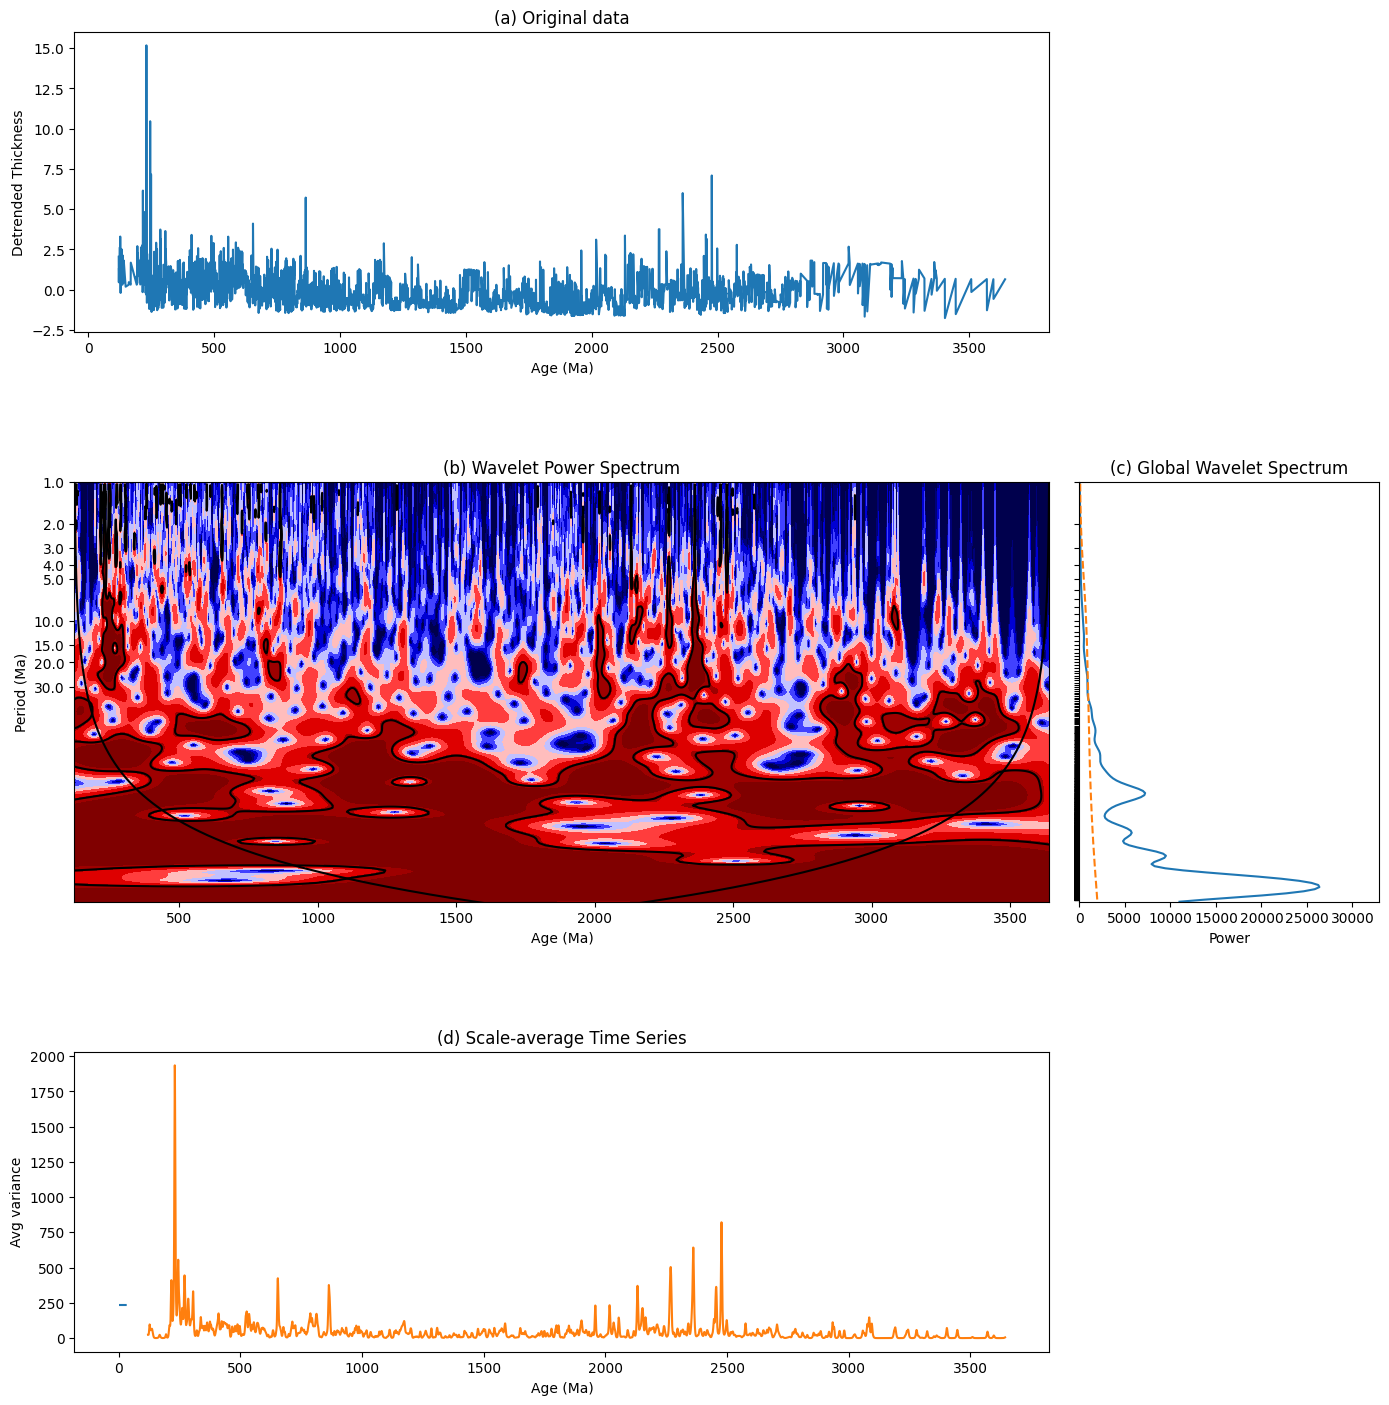

In [69]:
from plot_utils.wavelet_plot import wavelet_analysis_plot

wavelet_analysis_plot(
    t,
    dat_norm,
    time,
    period,
    power, 
    global_ws,
    global_signif,
    scaleavg_signif,
    scale_avg,
    sig95,
    coi,
    'Detrended Thickness'
)